# Test training

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from pathlib import Path
import json
import numpy as np
from tokenizers import Tokenizer

import torch
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))
from src.gpt.model import RMSNorm, RoPE, Attention, MLP, Block, GPT

Tiny test runs

In [12]:

from pathlib import Path
import os

PROJECT_ROOT = Path("~/Desktop/swGPT").expanduser()
os.chdir(PROJECT_ROOT)

print(os.getcwd())
path = Path("runs/2026-10-25_1213_tiny/metrics.jsonl")

if path.exists():
    print(f"Found file: {path.resolve()}")
    df = pd.read_json(path, lines=True)
else:
    print(f"File not found: {path.resolve()}")

/Users/marzioformica/Desktop/swGPT
Found file: /Users/marzioformica/Desktop/swGPT/runs/2026-10-25_1213_tiny/metrics.jsonl


<Axes: xlabel='step'>

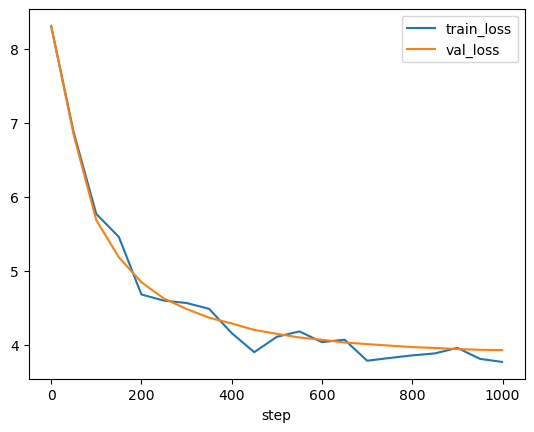

In [13]:
import pandas as pd

df = pd.read_json("runs/2026-10-25_1213_tiny/metrics.jsonl", lines=True)
df.plot(x="step", y=["train_loss", "val_loss"])

In [16]:
import pandas as pd
a = pd.read_json("runs/resume_a/metrics.jsonl", lines=True).set_index("step")
b = pd.read_json("runs/resume_b/metrics.jsonl", lines=True).groupby("step").last()
N = 120   # the step printed by "resumed from ... at step N"
cmp = pd.concat([a.train_loss, b.train_loss], axis=1, keys=["a", "b"]).loc[N:]
print((cmp.a - cmp.b).abs().max())

0.0006632804870605469


In [17]:
d = (cmp.a - cmp.b).abs()
print(d.head(10))              # the first steps after resuming
print(d.idxmax(), d.max())     # where the largest gap is

lr_a = a.lr.loc[N:]
lr_b = b.lr.loc[N:]
print((lr_a - lr_b).abs().max())   # should be ~0

step
120    0.000108
121    0.000079
122    0.000060
123    0.000002
124    0.000014
125    0.000085
126    0.000068
127    0.000007
128    0.000042
129    0.000130
dtype: float64
723 0.0006632804870605469
0.0


## Final model checks

In [ ]:
import math, torch
from gpt.config import load_config
from gpt.model import GPT, RoPE

cfg = load_config("/configs/tiny.yaml", data_dir="../data")
torch.manual_seed(0)
model = GPT(cfg).eval()
B, T = 4, cfg.context_len
idx = torch.randint(0, cfg.vocab_size, (B, T))

# 1) shapes and initial loss
logits, loss = model(idx, idx)
assert logits.shape == (B, T, cfg.vocab_size)
print("initial loss", loss.item(), "vs ln(V)", math.log(cfg.vocab_size))   # close, slightly above

# 2) parameter count against the hand formula
d, L, V, m = cfg.d_model, cfg.n_layer, cfg.vocab_size, cfg.mlp_mult
expected = V*d + L*(4*d*d + 2*m*d*d + 2*d) + d
print(sum(p.numel() for p in model.parameters()), expected)               # equal

# 3) causality: changing token t must not change logits before t
t = 20
idx2 = idx.clone()
idx2[:, t] = (idx2[:, t] + 1) % cfg.vocab_size
with torch.no_grad():
    l1, _ = model(idx)
    l2, _ = model(idx2)
print(torch.allclose(l1[:, :t], l2[:, :t], atol=1e-5))                    # True
print((l1[:, t:] - l2[:, t:]).abs().max() > 1e-4)                         # True: it does change from t on

# 4) every parameter gets a gradient
model.train()
_, loss = model(idx, idx)
loss.backward()
print(all(p.grad is not None for p in model.parameters()))                # True

# 5) RoPE: norm preserved, and scores depend only on relative position
rope = RoPE(head_dim=16, max_len=64)
x = torch.randn(2, 3, 10, 16)
print(torch.allclose(x.norm(dim=-1), rope(x).norm(dim=-1), atol=1e-5))    # True
q = torch.randn(1, 1, 1, 16).expand(1, 1, 32, 16)
k = torch.randn(1, 1, 1, 16).expand(1, 1, 32, 16)
S = rope(q)[0, 0] @ rope(k)[0, 0].T
print(all(torch.allclose(S.diagonal(o), S.diagonal(o)[0].expand_as(S.diagonal(o)), atol=1e-5)
          for o in range(-10, 11)))                                       # True

FileNotFoundError: [Errno 2] No such file or directory: '../configs/tiny.yaml'